Exact: 1000
Explicit dt=0.1: 101
Verlet dt=0.1: 101
Explicit dt=0.001: 10001
Verlet dt=0.001: 10001


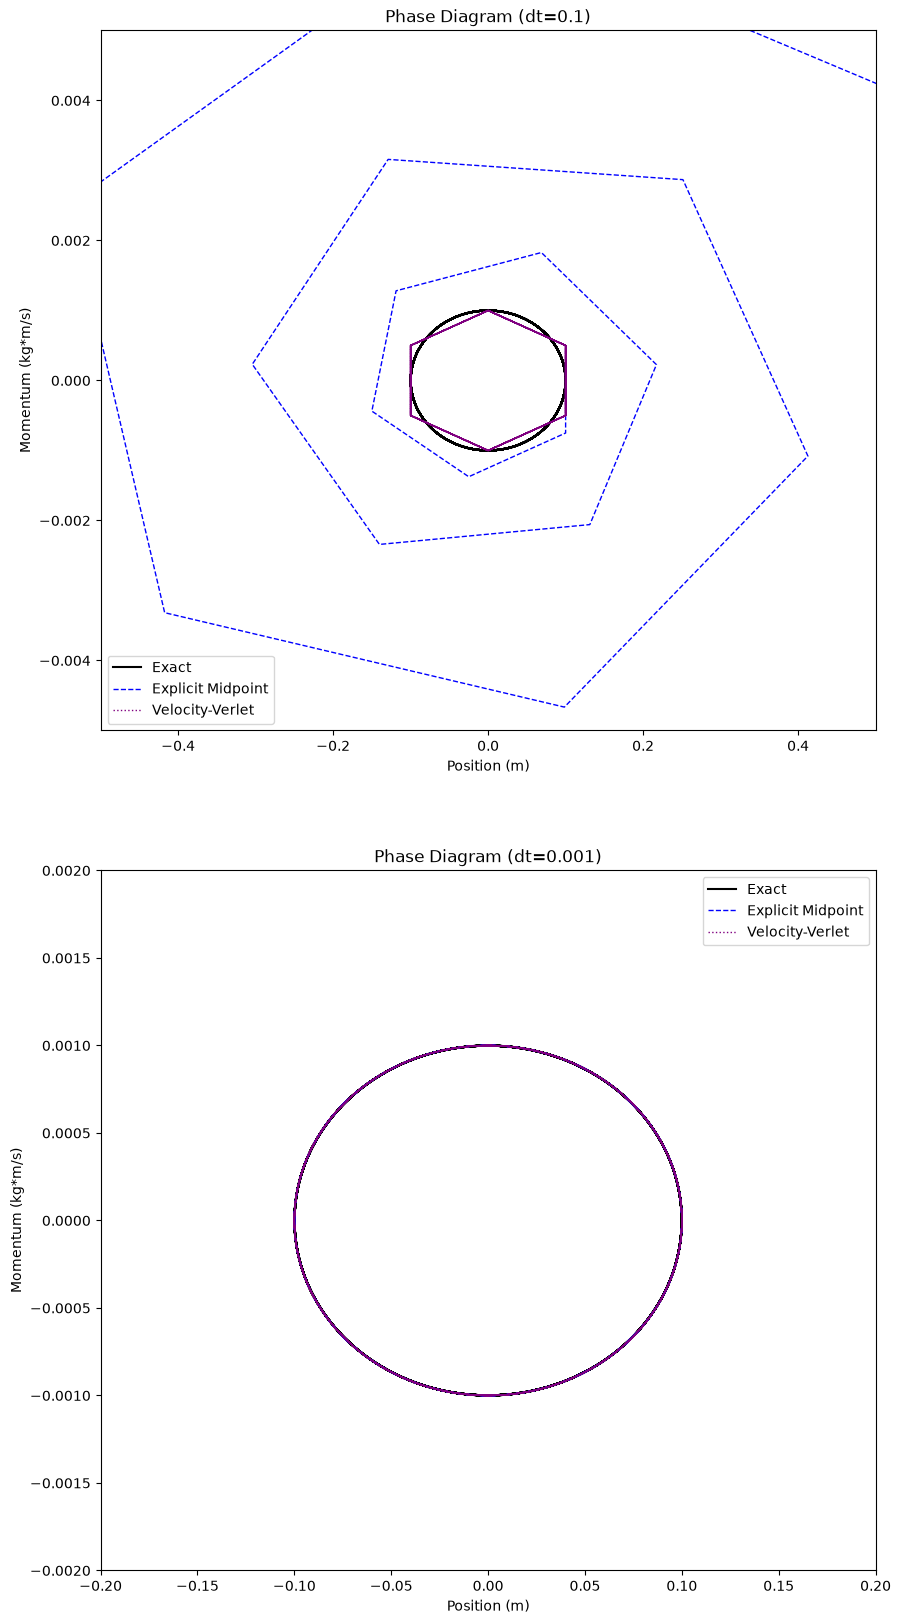

In [22]:
"""
Task: Plot the phase diagram of a harmonic string with
1. exact result
2. explicit midpoint method
3. velocity-Verlet algorithm
"""

import numpy as np
import matplotlib.pyplot as plt

# 1. Given parameters

m = 1e-3        # mass in kg
k = 0.1         # spring constant in N/m
omega = np.sqrt(k / m)  # angular frequency
x0 = 0        # initial displacement in m
p0 = 1e-3       # initial momentum in kg*m/s
A = 0.1         # amplitude of oscillation in m
T = 10          # total time in seconds
t = np.linspace(0, T, 1000)  # time array from 0 to 10 seconds
dt = 0.01       # time step in seconds
n = round(T / dt)  # number of time steps

# 2. Exact solution

def exact(t):
    x = A * np.sin(omega * t)  # exact displacement
    p = A * m * omega * np.cos(omega * t)  # exact momentum
    return x, p


# 3. Explicit midpoint method

def F(x):
    return -k * x   # force function for harmonic oscillator

def explicit(x0, p0, dt):
    x = [x0]        # list to store displacement values
    p = [p0]        # list to store momentum values
    for i in range(round(T / dt)):
        x_1 = x[i] + (dt / m) * (p[i] + F(x[i]) * dt / 2)    # x at the next time step
        p_1 = p[i] + F(x[i] + (p[i] / m) * dt / 2) * dt      # p at the next time step
        x.append(x_1)                               # append new displacement
        p.append(p_1)                               # append new momentum
    return x, p


# 4. Velocity-Verlet algorithm

def verlet(x0, p0, dt):
    x = [x0]        # list to store displacement values
    p = [p0]        # list to store momentum values
    for i in range(round(T / dt)):
       p_half = p[i] + F(x[i]) * dt / 2                      # half-step momentum
       x_1 = x[i] + (dt / m) * p_half                     # update displacement
       F_1 = F(x_1)                                   # force at new position
       p_1 = p_half + F_1 * dt / 2                        # update momentum
       x.append(x_1)                                   # append new displacement
       p.append(p_1)                                   # append new momentum
    return x, p


# 5. Collect results from all methods

x_exact, p_exact = exact(t)
x_explicit_01, p_explicit_01 = explicit(x0, p0, 0.1)
x_explicit_0001, p_explicit_0001 = explicit(x0, p0, 0.001)
x_verlet_01, p_verlet_01 = verlet(x0, p0, 0.1)
x_verlet_0001, p_verlet_0001 = verlet(x0, p0, 0.001)


# 6. Plotting the phase diagram

print("Exact:", len(x_exact))
print("Explicit dt=0.1:", len(x_explicit_01))
print("Verlet dt=0.1:", len(x_verlet_01))

print("Explicit dt=0.001:", len(x_explicit_0001))
print("Verlet dt=0.001:", len(x_verlet_0001))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 20))

ax1.plot(x_exact, p_exact, label='Exact', color='black')
ax1.plot(x_explicit_01, p_explicit_01, label='Explicit Midpoint', color='blue', linestyle='--', linewidth=1)
ax1.plot(x_verlet_01, p_verlet_01, label='Velocity-Verlet', color='purple', linestyle=':', linewidth=1)
ax1.set_title('Phase Diagram (dt=0.1)')
ax1.set_xlabel('Position (m)')
ax1.set_ylabel('Momentum (kg*m/s)')
ax1.set_xlim(-0.5, 0.5)
ax1.set_ylim(-0.005, 0.005)
ax1.legend()

ax2.plot(x_exact, p_exact, label='Exact', color='black')
ax2.plot(x_explicit_0001, p_explicit_0001, label='Explicit Midpoint', color='blue', linestyle='--', linewidth=1)
ax2.plot(x_verlet_0001, p_verlet_0001, label='Velocity-Verlet', color='purple', linestyle=':', linewidth=1)
ax2.set_title('Phase Diagram (dt=0.001)')
ax2.set_xlabel('Position (m)')
ax2.set_ylabel('Momentum (kg*m/s)')
ax2.set_xlim(-0.2, 0.2)
ax2.set_ylim(-0.002, 0.002)
ax2.legend()

fig.subplots_adjust(hspace=0.2)